![Logo SENATI](logo_senati.png)

**SENATI | Escuela de Tecnologías de la Información**  
**Taller: Machine Learning y Deep Learning**  
*Instructor: Ing. Gunar Castro Iñigo*  
**Estudiante:** _(escribe aquí tu nombre)_

---

# Sistema de estimación de pedidos de kits de robótica — caso práctico intermedio 01

**Contexto:** Una tienda educativa quiere anticipar pedidos semanales. El número de consultas y la inversión publicitaria pueden asociarse con más ventas; el indicador de campaña escolar toma 0 o 1.

**Objetivo:** aplicar regresión lineal múltiple desde la lectura de datos hasta una web pequeña con Flask.

**Datos:** `../datos/datos.csv` (simulados, no son registros reales).

| Paso | Qué se hace | Dónde |
|---|---|---|
| 1 | Explorar el CSV, ausentes y rangos | este cuaderno |
| 2 | Separar 80/20, entrenar, coeficientes, MAE y R² | este cuaderno (`../entrenar.py` hace lo mismo como script) |
| 3 | Aplicación web (Flask + HTML + CSS) y `modelo.json` | `../app.py`, `../templates/`, `../static/` |
| 4 | Pruebas obligatorias y conclusiones | este cuaderno + `../pruebas/` |

## Paso 1. Explorar el CSV

Columnas de entrada `X`: `consultas_web`, `inversion_publicidad_soles`, `campana_escolar`. Respuesta `y`: `pedidos_kits`.

| Variable | Rol | Significado en la vida real | Unidad |
|---|---|---|---|
| `consultas_web` | X | Mensajes/consultas que recibe la tienda por la web en la semana | consultas |
| `inversion_publicidad_soles` | X | Dinero gastado en publicidad esa semana | soles (S/) |
| `campana_escolar` | X | 1 si hay campaña escolar esa semana, 0 si no | 0 / 1 |
| `pedidos_kits` | **y** | Pedidos de kits de robótica que se concretan en la semana | pedidos |

`semana` es solo un código de registro: **no se usa para entrenar**.

**¿Cuál sería el peligro de usar esta predicción sin verificarla?** El peligro es tratar la estimación como una cifra segura: si se compra inventario o se contrata personal según ella, un error de unos pocos pedidos por semana puede causar faltantes o sobrantes. Además, los datos son simulados y el modelo solo conoce tres factores; no ve la competencia, los feriados, el precio ni el stock.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split

# El cuaderno está en notebooks/; el CSV está en ../datos/
# utf-8-sig quita la marca BOM que Excel agrega al guardar CSV.
datos = pd.read_csv('../datos/datos.csv', encoding='utf-8-sig')

print('Filas y columnas:', datos.shape)
display(datos.head())
print()
print('Valores ausentes por columna:')
print(datos.isna().sum())
print()
print('Filas duplicadas:', datos.duplicated().sum())
print('Códigos de registro únicos (semana):', datos['semana'].is_unique)

Filas y columnas: (110, 5)


,semana,consultas_web,inversion_publicidad_soles,campana_escolar,pedidos_kits
0,S001,31,600,1,22
1,S002,51,75,0,20
2,S003,27,900,0,17
3,S004,45,125,0,21
4,S005,40,225,1,16



Valores ausentes por columna:
semana                        0
consultas_web                 0
inversion_publicidad_soles    0
campana_escolar               0
pedidos_kits                  0
dtype: int64

Filas duplicadas: 0
Códigos de registro únicos (semana): True


In [2]:
columnas = ['consultas_web', 'inversion_publicidad_soles', 'campana_escolar']
objetivo = 'pedidos_kits'

display(datos[columnas + [objetivo]].describe().round(2))

# ¿Los datos respetan los rangos que validará la web?
rangos = {'consultas_web': (5, 70), 'inversion_publicidad_soles': (0, 1100), 'campana_escolar': (0, 1)}
for col, (minimo, maximo) in rangos.items():
    fuera = ((datos[col] < minimo) | (datos[col] > maximo)).sum()
    print(f'{col}: min={datos[col].min():g}, max={datos[col].max():g} '
          f'(válido {minimo:g}-{maximo:g}) -> filas fuera de rango: {fuera}')

# Limpieza: aquí no hay ausentes ni duplicados, pero dejamos el paso por si el CSV cambia.
datos = datos.dropna(subset=columnas + [objetivo]).drop_duplicates()
print('\nFilas después de la limpieza:', len(datos))

,consultas_web,inversion_publicidad_soles,campana_escolar,pedidos_kits
count,110.00,110.00,110.00,110.00
mean,32.22,577.73,0.51,19.36
std,18.69,323.26,0.50,7.73
min,5.00,0.00,0.00,3.00
25%,14.25,300.00,0.00,14.25
50%,30.50,600.00,1.00,20.00
75%,48.50,850.00,1.00,25.00
max,69.00,1100.00,1.00,41.00


consultas_web: min=5, max=69 (válido 5-70) -> filas fuera de rango: 0
inversion_publicidad_soles: min=0, max=1100 (válido 0-1100) -> filas fuera de rango: 0
campana_escolar: min=0, max=1 (válido 0-1) -> filas fuera de rango: 0

Filas después de la limpieza: 110


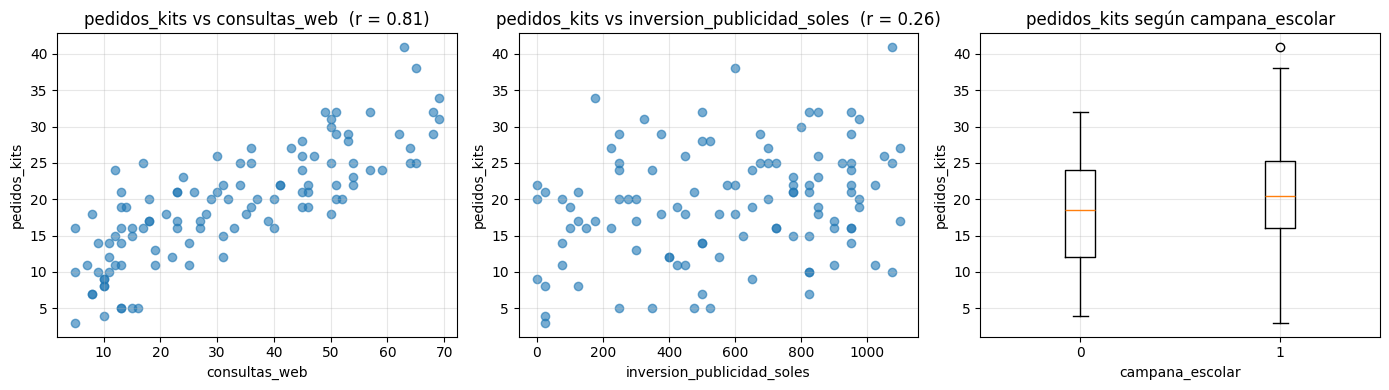

Correlación entre las X (si dos X se parecen mucho, cuesta separar su efecto):


,consultas_web,inversion_publicidad_soles,campana_escolar
consultas_web,1.00,-0.03,-0.15
inversion_publicidad_soles,-0.03,1.00,-0.04
campana_escolar,-0.15,-0.04,1.00


In [3]:
# Vistazo gráfico: cómo se relaciona cada X con y
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, col in zip(ejes[:2], ['consultas_web', 'inversion_publicidad_soles']):
    eje.scatter(datos[col], datos[objetivo], alpha=0.6)
    eje.set_xlabel(col)
    eje.set_ylabel(objetivo)
    eje.set_title(f'{objetivo} vs {col}  (r = {datos[col].corr(datos[objetivo]):.2f})')
    eje.grid(alpha=0.3)

binaria = 'campana_escolar'
ejes[2].boxplot([datos.loc[datos[binaria] == 0, objetivo], datos.loc[datos[binaria] == 1, objetivo]],
                tick_labels=['0', '1'])
ejes[2].set_xlabel(binaria)
ejes[2].set_ylabel(objetivo)
ejes[2].set_title(f'{objetivo} según {binaria}')
ejes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Correlación entre las X (si dos X se parecen mucho, cuesta separar su efecto):')
display(datos[columnas].corr().round(2))

**Qué observar:** las variables numéricas muestran tendencia creciente con la respuesta; la variable 0/1 se interpreta mejor como una comparación entre dos grupos. Las X casi no se correlacionan entre sí, lo que ayuda a que el modelo múltiple pueda separar el efecto de cada una.

## Paso 2. Separar 80 % / 20 % y entrenar

- **Variables usadas (X):** `consultas_web`, `inversion_publicidad_soles`, `campana_escolar`.
- **Variable a estimar (y):** `pedidos_kits`.
- **Separación:** 80 % entrenamiento / 20 % prueba con `random_state=42`. El modelo **nunca ve** las filas de prueba al entrenar; sirven para medir cómo se comportaría con datos nuevos.

In [4]:
X = datos[columnas]
y = datos[objetivo]

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print('Filas totales      :', len(datos))
print('Filas entrenamiento:', len(X_entrenamiento))
print('Filas prueba       :', len(X_prueba))

Filas totales      : 110
Filas entrenamiento: 88
Filas prueba       : 22


In [5]:
modelo = LinearRegression()
modelo.fit(X_entrenamiento, y_entrenamiento)

print(f'Intercepto: {modelo.intercept_:.4f}')
tabla = pd.DataFrame({'variable': columnas, 'coeficiente': modelo.coef_})
display(tabla.round(4))

formula = f'{modelo.intercept_:.2f}' + ''.join(
    f' {coef:+.4f}*{col}' for col, coef in zip(columnas, modelo.coef_))
print('\nFórmula:  pedidos_kits =', formula)

Intercepto: 1.5385


,variable,coeficiente
0,consultas_web,0.3463
1,inversion_publicidad_soles,0.0067
2,campana_escolar,5.0182



Fórmula:  pedidos_kits = 1.54 +0.3463*consultas_web +0.0067*inversion_publicidad_soles +5.0182*campana_escolar


**Cómo leer los coeficientes** (modelo entrenado con 88 filas; los valores cambian un poco si cambia la separación):

- **Intercepto ≈ 1.54 pedidos:** punto de partida de la fórmula cuando consultas = 0, publicidad = S/ 0 y no hay campaña. Es un punto matemático de partida; no hay semanas reales con 0 consultas (el mínimo del CSV es 5).
- **`consultas_web` ≈ +0.346:** con la misma publicidad y campaña, cada consulta adicional se asocia con ~0.35 pedidos más; unas 3 consultas más ≈ 1 pedido más. Es la variable con mayor peso (su correlación con los pedidos es 0.81).
- **`inversion_publicidad_soles` ≈ +0.0067:** cada S/ 100 adicionales se asocian con ~0.67 pedidos más. Efecto positivo pero pequeño (correlación 0.26).
- **`campana_escolar` ≈ +5.02:** a igualdad de consultas y publicidad, una semana con campaña escolar se asocia con unos 5 pedidos más que una sin campaña.

Son **asociaciones** observadas en datos simulados, no pruebas de causa: no se puede afirmar que duplicar la publicidad *cause* más pedidos.

MAE (prueba)        : 2.954 pedidos
R²  (prueba)        : 0.791
MAE sin modelo      : 6.661 pedidos  (siempre el promedio)
Promedio de pedidos_kits: 19.36  ->  MAE / promedio = 15.3%


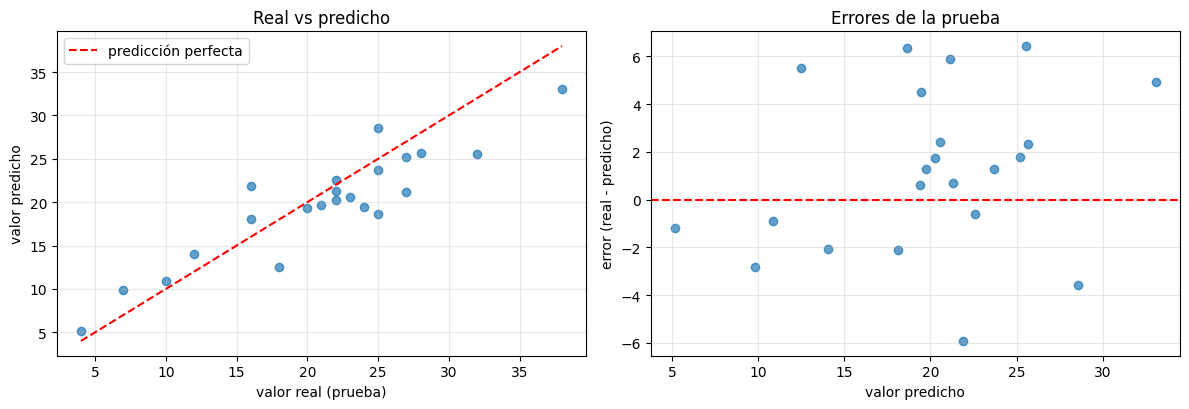

Mayor error absoluto en prueba: 6.44 pedidos


In [6]:
predicciones = modelo.predict(X_prueba)
mae = mean_absolute_error(y_prueba, predicciones)
r2 = r2_score(y_prueba, predicciones)

# Línea base: ¿qué error tendríamos sin modelo, prediciendo siempre el promedio de entrenamiento?
mae_base = mean_absolute_error(y_prueba, np.full(len(y_prueba), y_entrenamiento.mean()))

print(f'MAE (prueba)        : {mae:.3f} pedidos')
print(f'R²  (prueba)        : {r2:.3f}')
print(f'MAE sin modelo      : {mae_base:.3f} pedidos  (siempre el promedio)')
print(f'Promedio de pedidos_kits: {y.mean():.2f}  ->  MAE / promedio = {mae / y.mean():.1%}')

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ejes[0].scatter(y_prueba, predicciones, alpha=0.7)
limite = [min(y_prueba.min(), predicciones.min()), max(y_prueba.max(), predicciones.max())]
ejes[0].plot(limite, limite, 'r--', label='predicción perfecta')
ejes[0].set_xlabel('valor real (prueba)')
ejes[0].set_ylabel('valor predicho')
ejes[0].set_title('Real vs predicho')
ejes[0].legend()
ejes[0].grid(alpha=0.3)

residuos = y_prueba - predicciones
ejes[1].scatter(predicciones, residuos, alpha=0.7)
ejes[1].axhline(0, color='r', linestyle='--')
ejes[1].set_xlabel('valor predicho')
ejes[1].set_ylabel('error (real - predicho)')
ejes[1].set_title('Errores de la prueba')
ejes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Mayor error absoluto en prueba: {residuos.abs().max():.2f} pedidos')

**Interpretación en las unidades del problema**

- **MAE ≈ 2.95 pedidos:** en las 22 semanas de prueba, la estimación se equivocó en promedio por unos **3 pedidos por semana**. Frente a un promedio de ~19 pedidos, es un error típico de ~15 %. Sin modelo (predecir siempre el promedio) el MAE sería ≈ 6.7 pedidos, así que el modelo reduce el error a menos de la mitad.
- **R² ≈ 0.79:** el modelo explica cerca del **79 %** de la variación de los pedidos semanales; el ~21 % restante depende de factores que no están en los datos (o de azar). No significa que acierte el 79 % de las veces.
- El MAE es un promedio: hay semanas con errores mayores (el peor error en prueba fue ≈ 6 pedidos).
- Con solo 22 filas de prueba, las métricas dependen de la separación elegida; por eso abajo se repite la evaluación con validación cruzada.

In [7]:
# Comprobación extra: repetir la evaluación con 5 separaciones distintas (validación cruzada)
# para ver si las métricas dependen de la suerte de una sola separación.
kf = KFold(n_splits=5, shuffle=True, random_state=42)
mae_cv = -cross_val_score(LinearRegression(), X, y, cv=kf, scoring='neg_mean_absolute_error')
r2_cv = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2')
print('MAE por bloque:', mae_cv.round(2), '-> promedio', mae_cv.mean().round(2))
print('R²  por bloque:', r2_cv.round(3), '-> promedio', r2_cv.mean().round(3))

# ¿Ayudaría un modelo menos simple (términos al cuadrado e interacciones)?
extra = X.copy()
for i, a in enumerate(columnas):
    for b in columnas[i:]:
        extra[a + '*' + b] = X[a] * X[b]
r2_extra = cross_val_score(LinearRegression(), extra, y, cv=kf, scoring='r2')
print('R² promedio con términos extra:', r2_extra.mean().round(3), '(si no mejora, la línea basta)')

MAE por bloque: [2.95 2.28 2.28 3.14 2.33] -> promedio 2.6
R²  por bloque: [0.791 0.85  0.862 0.762 0.753] -> promedio 0.804
R² promedio con términos extra: 0.784 (si no mejora, la línea basta)


## Paso 3. Guardar `modelo.json` y aplicación web

Se guardan el intercepto y los coeficientes en `../modelo.json`. La app Flask (`../app.py`) lee ese archivo y calcula `y = intercepto + Σ coeficiente × valor`, sin necesidad de volver a entrenar ni de instalar scikit-learn para usar la web.

Archivos de la web (solo **Python + Flask + HTML + CSS**, sin JavaScript):
- `app.py`: rutas, validación de rangos y cálculo.
- `templates/index.html`: formulario con 3 campos con unidades, botón **Calcular**, resultado y advertencia.
- `static/estilos.css`: diseño.

Para abrirla, desde la carpeta del caso: `python app.py` y visitar http://127.0.0.1:5000.

In [8]:
contenido = {
    'caso': 'CASO 01',
    'descripcion': 'Sistema de estimación de pedidos de kits de robótica',
    'tipo_modelo': 'LinearRegression (scikit-learn)',
    'variables': columnas,
    'objetivo': objetivo,
    'unidad_objetivo': 'pedidos por semana',
    'intercepto': float(modelo.intercept_),
    'coeficientes': {k: float(v) for k, v in zip(columnas, modelo.coef_)},
    'rangos': {k: [float(a), float(b)] for k, (a, b) in rangos.items()},
    'metricas_prueba': {'MAE': float(mae), 'R2': float(r2)},
    'filas': {'total': int(len(datos)), 'entrenamiento': int(len(X_entrenamiento)),
              'prueba': int(len(X_prueba))},
    'separacion': {'proporcion_prueba': 0.2, 'random_state': 42},
    'nota': 'Datos simulados. Estimación educativa, no una cifra comercial.',
}
with open('../modelo.json', 'w', encoding='utf-8') as archivo:
    json.dump(contenido, archivo, indent=2, ensure_ascii=False)
print(Path('../modelo.json').read_text(encoding='utf-8'))

{
  "caso": "CASO 01",
  "descripcion": "Sistema de estimación de pedidos de kits de robótica",
  "tipo_modelo": "LinearRegression (scikit-learn)",
  "variables": [
    "consultas_web",
    "inversion_publicidad_soles",
    "campana_escolar"
  ],
  "objetivo": "pedidos_kits",
  "unidad_objetivo": "pedidos por semana",
  "intercepto": 1.5384729585592574,
  "coeficientes": {
    "consultas_web": 0.3463033562740661,
    "inversion_publicidad_soles": 0.006699109182241925,
    "campana_escolar": 5.018213367145449
  },
  "rangos": {
    "consultas_web": [
      5.0,
      70.0
    ],
    "inversion_publicidad_soles": [
      0.0,
      1100.0
    ],
    "campana_escolar": [
      0.0,
      1.0
    ]
  },
  "metricas_prueba": {
    "MAE": 2.954102420565232,
    "R2": 0.7910735136647091
  },
  "filas": {
    "total": 110,
    "entrenamiento": 88,
    "prueba": 22
  },
  "separacion": {
    "proporcion_prueba": 0.2,
    "random_state": 42
  },
  "nota": "Datos simulados. Estimación educativa, 

## Paso 4. Pruebas obligatorias

Se calcula cada caso de dos maneras para comprobar que dan lo mismo: con `modelo.predict` (scikit-learn) y con la fórmula leída de `modelo.json` (lo que hace la web).

In [9]:
pruebas = [('Prueba 1: 20 consultas, S/ 200, sin campaña', {'consultas_web': 20, 'inversion_publicidad_soles': 200, 'campana_escolar': 0}), ('Prueba 2: 55 consultas, S/ 800, con campaña', {'consultas_web': 55, 'inversion_publicidad_soles': 800, 'campana_escolar': 1})]

with open('../modelo.json', encoding='utf-8') as archivo:
    guardado = json.load(archivo)

for nombre, valores in pruebas:
    fila = pd.DataFrame([valores])[columnas]
    con_sklearn = modelo.predict(fila)[0]
    con_json = guardado['intercepto'] + sum(guardado['coeficientes'][k] * valores[k] for k in columnas)
    assert abs(con_sklearn - con_json) < 1e-9
    print(f'{nombre}')
    print(f'   scikit-learn: {con_sklearn:.4f}   |   modelo.json: {con_json:.4f}   ->  {con_json:.2f} pedidos')

Prueba 1: 20 consultas, S/ 200, sin campaña
   scikit-learn: 9.8044   |   modelo.json: 9.8044   ->  9.80 pedidos
Prueba 2: 55 consultas, S/ 800, con campaña
   scikit-learn: 30.9627   |   modelo.json: 30.9627   ->  30.96 pedidos


In [10]:
# ¿Tienen sentido? Comparación con los 5 registros más parecidos del CSV
# (misma categoría 0/1 y variables numéricas cercanas, medidas en desviaciones estándar).
binaria = 'campana_escolar'
numericas = [c for c in columnas if c != binaria]

def parecidos(valores, k=5):
    grupo = datos[datos[binaria] == valores[binaria]].copy()
    grupo['distancia'] = sum(((grupo[c] - valores[c]) / datos[c].std()) ** 2 for c in numericas) ** 0.5
    return grupo.nsmallest(k, 'distancia')

for nombre, valores in pruebas:
    vecinos = parecidos(valores)
    print(nombre)
    display(vecinos[['semana'] + columnas + [objetivo]].round(2))
    print(f'   Parecidos: promedio = {vecinos[objetivo].mean():.2f}, mín = {vecinos[objetivo].min():g}, máx = {vecinos[objetivo].max():g}\n')

Prueba 1: 20 consultas, S/ 200, sin campaña


,semana,consultas_web,inversion_publicidad_soles,campana_escolar,pedidos_kits
91,S092,15,250,0,5
85,S086,19,300,0,13
86,S087,25,75,0,11
88,S089,10,125,0,8
62,S063,13,350,0,5


   Parecidos: promedio = 8.40, mín = 5, máx = 13

Prueba 2: 55 consultas, S/ 800, con campaña


,semana,consultas_web,inversion_publicidad_soles,campana_escolar,pedidos_kits
17,S018,57,825,1,32
66,S067,49,850,1,32
61,S062,51,675,1,29
28,S029,41,825,1,22
30,S031,65,600,1,38


   Parecidos: promedio = 30.60, mín = 22, máx = 38



**Resultados de las pruebas obligatorias**

| Prueba | Entrada | Estimación |
|---|---|---|
| 1 | 20 consultas, S/ 200, sin campaña | **≈ 9.8 → 10 pedidos** |
| 2 | 55 consultas, S/ 800, con campaña | **≈ 31.0 → 31 pedidos** |

**¿Tienen sentido?** Sí. La prueba 2 supera a la 1 por mucho, como se espera con más consultas, más publicidad y campaña. Contra semanas parecidas del CSV: las 5 más cercanas a la prueba 1 tuvieron entre 5 y 13 pedidos (promedio 8.4) y las de la prueba 2, entre 22 y 38 (promedio 30.6). Ambas estimaciones caen dentro de esos rangos y a menos de ~1.5 pedidos del promedio de sus vecinas.

**¿Cuándo podría fallar?** (1) Si se usa fuera de los rangos de entrenamiento (consultas 5–70, publicidad S/ 0–1100): el modelo extrapolaría una línea sin respaldo. (2) Si cambia el contexto (nuevo competidor, feriado, quiebre de stock): el modelo no los conoce. (3) En semanas atípicas: el error individual puede superar con facilidad el MAE de ~3 pedidos. (4) Porque los datos son simulados.

## Explicación del trabajo (10 líneas)

1. Objetivo: estimar los **pedidos semanales de kits de robótica** (y) con regresión lineal múltiple.
2. Variables X: `consultas_web`, `inversion_publicidad_soles` y `campana_escolar` (0/1); `semana` solo identifica filas.
3. Datos: 110 semanas simuladas, sin valores ausentes ni duplicados, dentro de los rangos del enunciado.
4. Reservé 20 % para prueba (22 filas) y entrené con 80 % (88 filas), con `random_state=42` para repetir el resultado.
5. Entrené `LinearRegression`: pedidos ≈ 1.54 + 0.346·consultas + 0.0067·publicidad + 5.02·campaña.
6. Las consultas pesan más: ~3 consultas más se asocian con ~1 pedido más; S/ 100 de publicidad, con ~0.7 pedidos.
7. En prueba obtuve MAE ≈ 2.95 pedidos (error típico de unos 3 por semana) y R² ≈ 0.79 (explica ~79 % de la variación).
8. Guardé el intercepto y los coeficientes en `modelo.json`; la app Flask los lee y aplica la fórmula sin reentrenar.
9. La web valida rangos (consultas 5–70, publicidad S/ 0–1100, campaña 0/1) y no usa JavaScript.
10. Pruebas: 20 consultas/S/ 200/sin campaña ≈ 10 pedidos; 55 consultas/S/ 800/con campaña ≈ 31 pedidos.

## Conclusiones y límites del modelo

- **Datos simulados:** el modelo refleja el generador de datos, no una tienda real; sirve para practicar, no para decidir inventario.
- **Error típico de ~3 pedidos (≈ 15 %):** en una semana cualquiera la estimación puede fallar por más; conviene comunicarla como rango (p. ej. 10 ± 3).
- **Rangos de validez:** fuera de 5–70 consultas y S/ 0–1100 de publicidad, el modelo extrapolaría sin respaldo; por eso la web lo bloquea.
- **Relación lineal:** supone efectos constantes (cada consulta suma lo mismo). Probé agregar términos cuadráticos e interacciones y no mejoró la validación cruzada (R² 0.78 vs 0.80), así que la línea basta para estos datos.
- **Asociación ≠ causa:** el coeficiente de publicidad no demuestra que gastar más produzca más pedidos.
- **Factores ausentes:** precio, competencia, feriados, stock, calidad de las consultas. Con datos reales habría que reentrenar y validar periódicamente.